# Structured-kernel KRR: learning curves to $n = 10^9$

The kernel is the one in `structured_rf.py`,
$$k(z,z') = k_{\rm even}(c,c')\,\frac{x_q\cdot x_q'}{d\,v},\qquad
k_{\rm even}(c,c') = \tfrac12\big[e^{-|c-c'|^2/2w^2}+e^{-|c+c'|^2/2w^2}\big],$$
with $c=[x_1..x_L, y_1..y_L]$ (the query is not in $c$). It has the two exact symmetries of the
target: linear in $x_q$, even in the context. Three consequences make its eigenstructure cheap
(`structured_theory.py`; each one is tested in `test_structured_theory.py`):

1. $x_q$ is independent of the context, so eigen$(k)$ = eigen$(k_{\rm even})$ × eigen(query-linear).
2. Only **even** context levels exist: $\cosh(c\cdot c'/w^2)$.
3. Kernel and data are invariant under permuting positions and under flipping the sign of one
   $(x_i,y_i)$ pair, so **all target power lives in the invariant sector**: sums over distinct positions
   of even per-position monomials. That is 21 functions at level 2 and 357 at level 4 for $d=5$.
   Everything else only enters through (eigenvalue, multiplicity), which is what makes
   $n = 10^9$ cheap.

**Stronger than (3): the O(L) symmetry.** The kernel only sees $c\cdot c'=\mathrm{tr}(Z^\top Z')$ and
$|c|^2$ for $Z=[X\ y]\in\mathbb R^{L\times(d+1)}$, and the data law depends on $Z$ only through
$M=Z^\top Z$ (Wishart given $\beta$). So both are invariant under $Z\to QZ$ for any rotation $Q\in O(L)$, and
every power-carrying eigenfunction is a polynomial in the 21 entries of $M$. The degree-$(2k+1)$ modes are
the degree-$k$ polynomials. The degree-9 floor therefore needs 12,650 functions rather than ~64,000
(`ol_theory.py`). Moments come from the exact Wishart Stein recursion, and the kernel on $M$ from the
zonal-polynomial formula for $\int_{O(L)}(\mathrm{tr}\,Z^\top QZ')^{2k}dQ$. It is checked against the
earlier engine through degree 9 at $d=2$ (`test_ol_theory.py`).

The theory is the S-expansion within each level, with eigenlearning (ID) and its OOD version on top.
The only approximation beyond the S-expansion is the level-$\ge 4$ **zero-power** bulk, treated as an
independent-coordinate staircase. It only affects $\kappa$, and only once level-4 modes are being
learned.

**`WHITEN_X`**: every context has $\sum_i x_i x_i^\top = c\,I_d$ exactly ($c = L v$ by default, so
marginals are unchanged). Ridge is then exactly degree 3, $(c+\epsilon^2)^{-1}\sum_a S_a x_{q,a}$. The
moments switch to the Monte Carlo backend, because positions are no longer independent.

## Setup (Colab A100; also runs locally)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os, getpass
try:
    from google.colab import userdata
    GIT_TOKEN = userdata.get('GIT_TOKEN')
except Exception:
    GIT_TOKEN = getpass.getpass('GitHub PAT: ')
GIT_USER = "JoeyTurn"
GIT_REPO = "kernel_ICL"

!git clone https://{GIT_TOKEN}@github.com/{GIT_USER}/{GIT_REPO}.git

sys.path.insert(0, "/content/kernel_ICL")
sys.path.insert(0, "/content/kernel_ICL/expts/rf_scaling")
RESULTPATH = "/content/drive/MyDrive/results/structured_kernel"
os.makedirs(RESULTPATH, exist_ok=True)

Mounted at /content/drive
GitHub PAT: ··········
Cloning into 'kernel_ICL'...
remote: Enumerating objects: 1010, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 1010 (delta 20), reused 34 (delta 15), pack-reused 967 (from 1)
Receiving objects: 100% (1010/1010), 56.31 MiB | 19.19 MiB/s, done.
Resolving deltas: 100% (544/544), done.


In [ ]:
import os, sys, math, time, pickle
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt

if not os.path.exists("/content/kernel_ICL"):
    ROOT = Path.cwd()
    while ROOT != ROOT.parent and not (ROOT / "kernels_can_icl" / "__init__.py").exists():
        ROOT = ROOT.parent
    for p in (ROOT, ROOT / "expts" / "rf_scaling"):
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
    RESULTPATH = str(ROOT / "expts" / "rf_scaling" / "results" / "structured_kernel")
    os.makedirs(RESULTPATH, exist_ok=True)

import kicl_floor as KF
import structured_theory as ST
import ol_theory as OL
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

device: cuda NVIDIA A100-SXM4-80GB


## Configuration

In [ ]:
# --- setting (defaults = the old run_eigenlearning_fixed_tasks_multi_dim_OOD figure) ---
DIM       = 5
L_CFG     = 8                  # context length INCLUDING the query -> L = 7 in-context pairs
EPS2      = 0.1                # label noise variance
SIGMA_X2  = None               # None -> 1/(d (L_cfg-1)) = 1/35, the task_distrs default the old notebook used
T         = 16                 # pool size
POOL_KIND = "whiten"           # any kicl_floor.make_tasks kind
POOL_SEED = 0

WIDTH     = 3.0                # k_even width w (old notebook: GaussianKernel kernel_width=3)
RIDGE     = 0.01               # absolute ridge on the n x n Gram (kernel diagonal is O(1))
MAX_LEVEL = 8                  # context level 8 = data degree 9 (4 -> degree 5, 6 -> degree 7)

WHITEN_X     = True           # sum_i x_i x_i^T = WHITEN_SCALE * I exactly in every context
WHITEN_SCALE = None            # None -> L v (keeps each x_i's marginal variance at v)

# --- theory / training ---
N_THEORY  = np.logspace(1, 18, 700)   # degree-9 modes need n ~ 1e17-1e18 at ridge 0.01
NS        = [10, 20, 40, 80, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, 30000, 40000, 50000, 60000, 70000, 80000]  # trimmed to N_MAX
TRIALS    = 20
N_TEST    = 8192
ORACLE_MC = 100_000
RUN_KRR   = True
RUN_L_SWEEP = True             # captured power per degree vs L (d=3, cheap)
RUN_EMP_LEARN = True           # measure the trained kernel's learnabilities (one extra fit + MC projection)
LEARN_N      = 30000#[10, 20, 40, 80, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, 30000]           # n for that fit (trimmed to N_MAX)
EMP_LEARN_MC = 200_000         # contexts in the projection
RUN_OVERLAP  = True            # cos(f_hat, oracle), theory + one fit per n
OVERLAP_TRIALS = 2
OVERLAP_MC   = 100_000         # contexts per measured overlap
PROJ_MC      = 200_000         # contexts for the oracles' mode coefficients (theory side)

SMOKE = bool(int(os.environ.get("STRUCTURED_SMOKE", "0")))
if SMOKE:
    NS, TRIALS, N_TEST, ORACLE_MC, LEARN_N = [50, 400], 2, 512, 4000, 400
    MAX_LEVEL = MAX_LEVEL if WHITEN_X else 4       # Gaussian-x degree 9 is a GPU job

cfg = KF.KICLConfig(dim=DIM, L_cfg=L_CFG, sigma_sq=EPS2,
                    sigma_x2=(1.0 / (DIM * (L_CFG - 1)) if SIGMA_X2 is None else SIGMA_X2), name="structured")
N_MAX = ST.StructuredKRR.max_n(DEVICE)
NS = [n for n in NS if n <= N_MAX]
LEARN_N = min(LEARN_N, N_MAX)
TAG = (f"d{DIM}_L{L_CFG}_e{EPS2:g}_T{T}_{POOL_KIND}_s{POOL_SEED}_w{WIDTH:g}_r{RIDGE:g}"
       f"{'_whiten' if WHITEN_X else ''}")
print(cfg.describe()); print(f"N_MAX (memory) = {N_MAX:,}; NS = {NS}")

structured: d=5 L_cfg=8 (L=7 pairs) e=0.1 v=0.02857 sigma_beta2=1.0 D=47 norm2=0.24286
N_MAX (memory) = 28,416; NS = [10, 20, 40, 80, 100, 200, 500, 1000, 2000, 5000, 10000, 20000]


## Pool, theory, oracles
Degree 9 with Gaussian $x$ at $d=5$ needs the GPU and the high-RAM runtime. The Wishart moments over
$9^5$ Gauss-Hermite nodes and two 12,650² Grams dominate, a few minutes on an A100. With `WHITEN_X` it is
~30 s.

In [ ]:
torch.manual_seed(POOL_SEED)
betas = KF.draw_betas(T, cfg, POOL_KIND, torch.device("cpu"))       # ONE pool: theory, KRR and oracles

t0 = time.time()
theory = OL.OLTheory(cfg, WIDTH, max_level=MAX_LEVEL, whiten=WHITEN_X, wscale=WHITEN_SCALE, device=DEVICE)
sy = theory.eigsys(betas)
curve = theory.curves(sy, N_THEORY, RIDGE)
print(f"theory: {len(sy['lam'])} invariant modes + {len(sy['bulk']['lam'])} bulk bins, "
      f"orthonormality err {sy['orth_err']:.1e}, {time.time()-t0:.1f}s total")

FLOORS = {cut: theory.floors(sy, cut) for cut in range(0, MAX_LEVEL + 1, 2)}
t0 = time.time()
ORC = ST.oracle_mse(cfg, betas, ORACLE_MC, seed=1, whiten=WHITEN_X, wscale=WHITEN_SCALE)
print(f"oracles ({time.time()-t0:.0f}s):", {k: round(v, 4) for k, v in ORC.items()})
print("\nn -> infinity floors (all invariant modes up to the cut learned):")
for cut, (fi, fo) in FLOORS.items():
    print(f"  degree <= {cut+1}:  ID {fi:.4f}   OOD {fo:.4f}")
print(f"  Ridge            ID {ORC['ridge_id']:.4f}   OOD {ORC['ridge_ood']:.4f}")
print(f"  dMMSE            ID {ORC['dmmse_id']:.4f}   OOD {ORC['dmmse_ood']:.4f}")
o = curve["OOD"]
mins = [k for k in range(1, len(o) - 1) if o[k] < o[k - 1] and o[k] <= o[k + 1]]
if mins:
    i = mins[0]; j = i + int(np.argmax(o[i:]))
    print(f"\ntheory OOD curve: dip to {o[i]:.4f} at n~{N_THEORY[i]:.1e}, rise to {o[j]:.4f} at "
          f"n~{N_THEORY[j]:.1e}, {o[-1]:.4f} at n={N_THEORY[-1]:.0e}")
else:
    print(f"\ntheory OOD curve is monotone here: {o[0]:.4f} -> {o[-1]:.4f}")

  O(L) engine ready: degree <= 4 in M (12,650 functions, data degree 9), 0.3s
  whitened moments (closed form): 4.1s
  O(L) eigensystem: 210 modes, orthonormality err 6.1e-12, 3.1s
theory: 210 invariant modes + 1734 bulk bins, orthonormality err 6.1e-12, 9.4s total
oracles (1s): {'ridge_id': 0.6028, 'ridge_ood': 0.6058, 'dmmse_id': 0.4974, 'dmmse_ood': 0.7562}

n -> infinity floors (all invariant modes up to the cut learned):
  degree <= 1:  ID 1.0000   OOD 1.0000
  degree <= 3:  ID 0.6059   OOD 0.6104
  degree <= 5:  ID 0.5570   OOD 0.7216
  degree <= 7:  ID 0.5343   OOD 0.7315
  degree <= 9:  ID 0.5224   OOD 0.7230
  Ridge            ID 0.6028   OOD 0.6058
  dMMSE            ID 0.4974   OOD 0.7562

theory OOD curve: dip to 0.6199 at n~7.3e+05, rise to 0.7261 at n~1.1e+13, 0.7230 at n=1e+18


In [ ]:
print("theory curve by decade (normalized test MSE):")
for n in [1e2, 1e3, 1e4, 1e5, 1e6, 1e8, 1e10, 1e12]:
    k = int(np.argmin(np.abs(np.log(N_THEORY / n))))
    print(f"  n = {n:8.0e}   ID {curve['ID'][k]:.4f}   OOD {curve['OOD'][k]:.4f}")

theory curve by decade (normalized test MSE):
  n =    1e+02   ID 1.0923   OOD 1.1005
  n =    1e+03   ID 0.9763   OOD 0.9963
  n =    1e+04   ID 0.7530   OOD 0.7600
  n =    1e+05   ID 0.6312   OOD 0.6384
  n =    1e+06   ID 0.5983   OOD 0.6202
  n =    1e+08   ID 0.5580   OOD 0.7063
  n =    1e+10   ID 0.5507   OOD 0.7107
  n =    1e+12   ID 0.5348   OOD 0.7202


### Top modes
Eigenvalue, level, the invariant feature that dominates the mode, and its target power
$\sum_b v_{k,b}^2$ in normalized units.

In [ ]:
order = np.argsort(sy["lam"])[::-1]
print(f"{'lambda':>10}  lvl  {'dominant feature':24s} power")
for k in order[:25]:
    print(f"{sy['lam'][k]:10.3e}  {sy['level'][k]:3d}  {sy['dom'][k]:24s} {float((sy['v_tr'][k]**2).sum()):.4f}")

    lambda  lvl  dominant feature         power
 1.485e-01    0  1                        0.0000
 1.095e-04    2  M[yy]                    0.0189
 1.572e-05    2  M[x4y]                   0.0784
 1.572e-05    2  M[x1y]                   0.0784
 1.572e-05    2  M[x2y]                   0.0784
 1.572e-05    2  M[x0y]                   0.0784
 1.410e-05    2  M[yy]                    0.0615
 6.745e-08    4  M[yy]*M[yy]              0.0010
 1.372e-08    4  M[x0y]*M[yy]             0.0014
 1.223e-08    4  M[x1y]*M[yy]             0.0001
 9.915e-09    4  M[x3y]*M[yy]             0.0005
 8.500e-09    4  M[x2y]*M[yy]             0.0009
 6.881e-09    4  M[yy]*M[yy]              0.0024
 2.011e-09    4  M[x1y]*M[yy]             0.0017
 1.565e-09    4  M[x0y]*M[x1y]            0.0019
 1.519e-09    4  M[x1y]*M[yy]             0.0044
 1.297e-09    4  M[x2y]*M[yy]             0.0046
 1.101e-09    4  M[x0y]*M[yy]             0.0082
 1.095e-09    4  M[x2y]*M[x2y]            0.0052
 1.032e-09    4  M[x2

## Learnabilities

Eigenlearning gives every mode a learnability
$$\mathcal L_i(n)=\frac{\lambda_i}{\lambda_i+\kappa(n)},\qquad
\sum_i m_i\frac{\lambda_i}{\lambda_i+\kappa}+\frac{\delta}{\kappa}=n,$$
with one global $\kappa(n)$ fixed by the **whole** spectrum (bulk included, with multiplicities), so the
curves below are an acquisition ladder: larger $\lambda$ crosses $\mathcal L=1/2$ first. Because
$\mathcal L=1/2$ means exactly $\kappa=\lambda_i$, the acquisition point needs no root finding,
$n_{1/2,i}=\sum_j m_j\lambda_j/(\lambda_j+\lambda_i)+\delta/\lambda_i$.

Modes are aggregated per data degree by **target power**, $\mathcal L_p(n)=\sum_{i\in p}p_i\mathcal L_i/\sum_{i\in p}p_i$
with $p_i=\sum_b v_{i,b}^2$: a degree counts as learned when its share of the target is. This is the same
$\mathcal L_{p,m}$ that multiplies $v_{p,m}\chi_{p,m}(\beta)$ in the task-space predictor, so these curves
say which task-space term is live at a given $n$, and the degree floors in the learning-curve plot are
reached where the corresponding $\mathcal L_p\to1$.

In [ ]:
learn = theory.learnability(sy, N_THEORY, RIDGE)
print(f"{len(learn['lam'])} power-carrying modes (x{DIM} query axes); target power "
      f"{learn['total_power']:.4f} of {sy['sig_p']:.4f} available\n")
print(f"{'degree':>6} {'modes':>6} {'power share':>12} {'lambda range':>22} {'n at L=1/2':>12}")
for p, Lp in learn["deg_L"].items():
    m = learn["deg"] == p
    lam_d = learn["lam"][m]
    print(f"{p:6d} {int(m.sum()):6d} {learn['deg_power'][p]/sy['sig_p']:12.4f} "
          f"{lam_d.min():10.2e}-{lam_d.max():9.2e} {learn['deg_n_half'][p]:12.3e}")
print("\ntop modes by target power:")
print(f"{'lambda':>10} {'deg':>4}  {'dominant feature':24s} {'power':>9} {'n at L=1/2':>12}")
for k in np.argsort(learn["power"])[::-1][:15]:
    print(f"{learn['lam'][k]:10.3e} {learn['deg'][k]:4d}  {sy['dom'][k]:24s} "
          f"{learn['power'][k]:9.2e} {learn['n_half'][k]:12.3e}")

210 power-carrying modes (x5 query axes); target power 0.4776 of 0.5882 available

degree  modes  power share           lambda range   n at L=1/2
     1      1       0.0000   1.49e-01- 1.49e-01    1.000e+01
     3      6       0.6699   1.41e-05- 1.10e-04    1.524e+03
     5     21       0.0832   6.28e-11- 6.75e-08    7.069e+06
     7     56       0.0385   3.52e-15- 3.66e-11    8.246e+10
     9    126       0.0203   2.26e-20- 1.78e-14    6.353e+14

top modes by target power:
    lambda  deg  dominant feature             power   n at L=1/2
 1.572e-05    3  M[x4y]                    7.84e-02    1.591e+03
 1.572e-05    3  M[x1y]                    7.84e-02    1.591e+03
 1.572e-05    3  M[x2y]                    7.84e-02    1.591e+03
 1.572e-05    3  M[x0y]                    7.84e-02    1.591e+03
 1.410e-05    3  M[yy]                     6.15e-02    1.728e+03
 1.095e-04    3  M[yy]                     1.89e-02    3.362e+02
 1.032e-09    5  M[x2y]*M[yy]              8.63e-03    9.795e+06
 

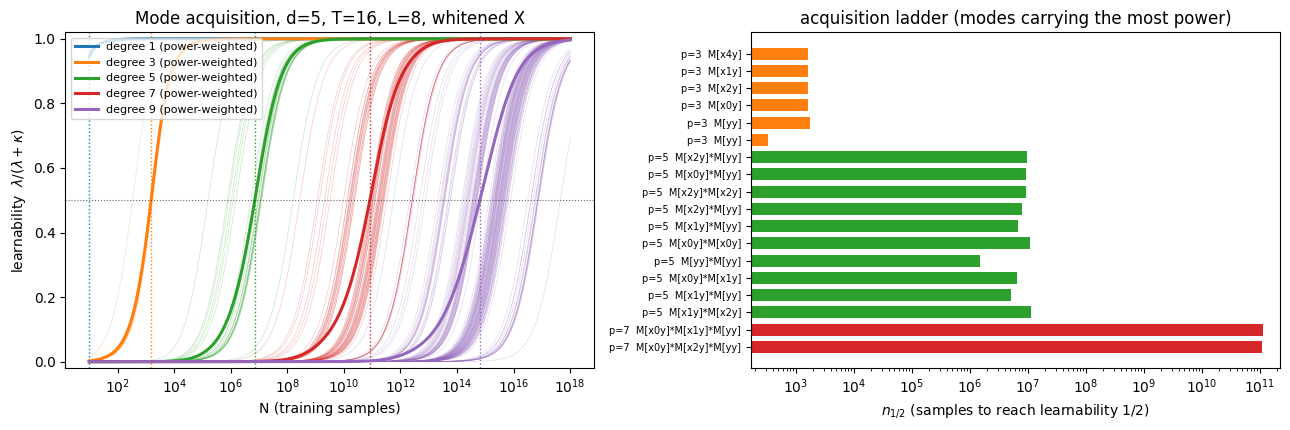

learned fraction of the target power:
  n=   1e+02  kappa= 4.46e-04  total 0.0341   p1:0.997  p3:0.041  p5:0.000  p7:0.000  p9:0.000
  n=   1e+04  kappa= 1.47e-06  total 0.7566   p1:1.000  p3:0.917  p5:0.002  p7:0.000  p9:0.000
  n=   1e+06  kappa= 1.00e-08  total 0.8410   p1:1.000  p3:0.999  p5:0.160  p7:0.000  p9:0.000
  n=   1e+09  kappa= 9.97e-12  total 0.9290   p1:1.000  p3:1.000  p5:0.992  p7:0.048  p9:0.000
  n=   1e+12  kappa= 1.02e-14  total 0.9696   p1:1.000  p3:1.000  p5:1.000  p7:0.877  p9:0.019
  n=   1e+15  kappa= 9.80e-18  total 0.9893   p1:1.000  p3:1.000  p5:1.000  p7:1.000  p9:0.574
  n=   1e+18  kappa= 1.00e-20  total 0.9999   p1:1.000  p3:1.000  p5:1.000  p7:1.000  p9:0.997


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
cols = {p: plt.cm.tab10(i) for i, p in enumerate(learn["deg_L"])}
for k in range(len(learn["lam"])):                       # every power-carrying mode, faint
    if learn["power"][k] > 1e-14:
        ax[0].semilogx(N_THEORY, learn["L"][:, k], color=cols[learn["deg"][k]], lw=0.5, alpha=0.25)
for p, Lp in learn["deg_L"].items():                     # power-weighted per degree
    ax[0].semilogx(N_THEORY, Lp, color=cols[p], lw=2.2, label=f"degree {p} (power-weighted)")
    if np.isfinite(learn["deg_n_half"][p]):
        ax[0].axvline(learn["deg_n_half"][p], color=cols[p], ls=":", lw=1.0)
ax[0].axhline(0.5, color="k", lw=0.8, ls=":", alpha=0.6)
ax[0].set_xlabel("N (training samples)"); ax[0].set_ylabel(r"learnability  $\lambda/(\lambda+\kappa)$")
ax[0].set_ylim(-0.02, 1.02); ax[0].legend(fontsize=8, loc="upper left")
ax[0].set_title(f"Mode acquisition, d={DIM}, T={T}, L={L_CFG}" + (", whitened X" if WHITEN_X else ""))

top = np.argsort(learn["power"])[::-1][:18][::-1]        # ladder: n_half of the strongest modes
ax[1].barh(np.arange(len(top)), learn["n_half"][top], color=[cols[learn["deg"][k]] for k in top],
           height=0.7, log=True)
ax[1].set_yticks(np.arange(len(top)))
ax[1].set_yticklabels([f"p={learn['deg'][k]}  {sy['dom'][k][:22]}" for k in top], fontsize=7)
ax[1].set_xlabel(r"$n_{1/2}$ (samples to reach learnability 1/2)")
ax[1].set_xlim(max(1.0, 0.5 * learn["n_half"][top].min()), 2 * learn["n_half"][top].max())
ax[1].set_title("acquisition ladder (modes carrying the most power)")
plt.tight_layout()
FIGDIR = os.path.join(RESULTPATH, "figs"); os.makedirs(FIGDIR, exist_ok=True)
plt.savefig(os.path.join(FIGDIR, f"learnability_{TAG}.pdf"), bbox_inches="tight")
plt.show()

print("learned fraction of the target power:")
for n in [1e2, 1e4, 1e6, 1e9, 1e12, 1e15, 1e18]:
    k = int(np.argmin(np.abs(np.log(N_THEORY / n))))
    per_deg = "  ".join(f"p{p}:{learn['deg_L'][p][k]:.3f}" for p in learn["deg_L"])
    print(f"  n={n:8.0e}  kappa={learn['kappa'][k]:9.2e}  total {learn['learned_power'][k]/learn['total_power']:.4f}   {per_deg}")

## Eigencoefficients: Table 2 corrected, organized by data degree

Whitened coordinates: $\tilde x = x/\sqrt v$, $\tilde\beta=\sqrt v\,\beta$, $\tau=\|\tilde\beta\|^2+\epsilon^2$,
query axis $b$. For each data degree $p$, $F_p$ is **every** invariant feature of that degree and
$F_<$ is everything below it.
$$\Gamma_p=\mathrm{Cov}(F_p)-\mathrm{Cov}(F_p,F_<)\mathrm{Cov}(F_<)^{-1}\mathrm{Cov}(F_<,F_p),\qquad
V_p=\mathbb E[y^\star F_p]-\mathrm{Cov}(F_p,F_<)\mathrm{Cov}(F_<)^{-1}\mathbb E[y^\star F_<].$$
The kernel's within-degree metric $W_p$ fixes the eigenbasis: $W^{1/2}\Gamma_pW^{1/2}=U\Lambda U^\top$,
$\lambda_k=\mathrm{pref}\cdot\Lambda_k/d$, and $v_k=U_k^\top W^{1/2}V_p/\sqrt{\Lambda_k}$. **The per-mode
coefficients depend on the kernel**, through $W$. What is kernel-free is the captured power
$P_p=V_p^\top\Gamma_p^{-1}V_p=\sum_k v_k^2$.

**p = 1:** $v=\tilde\mu_b$.

**p = 3: closed form, exact at every $L$ and for every pool.** Take $A=\sum_i y_i^2$,
$B_a=\sum_i y_i\tilde x_{ia}$ and $C_{ac}=\sum_i\tilde x_{ia}\tilde x_{ic}$. Then:
- overlaps: $V_A=L\,\mathrm{Cov}(\tau,\tilde\beta_b)$, $V_B=L\,\tilde\Sigma_{\cdot b}$, $V_C=0$
- $\mathrm{Cov}(A,A)=2L\,\mathbb E\tau^2+L^2\mathrm{Var}\,\tau$
- $\mathrm{Cov}(A,B)=2L\,\mathbb E[\tau\tilde\beta]+L^2\mathrm{Cov}(\tau,\tilde\beta)$
- $\mathrm{Cov}(B,B)=L(\tilde M_2+\bar\tau I)+L^2\tilde\Sigma$
- $\mathrm{Cov}(C_{ac},A)=2L\tilde M_{2,ac}$
- $\mathrm{Cov}(C_{ac},B_e)=L(\tilde\mu_a\delta_{ce}+\tilde\mu_c\delta_{ae})$
- $\mathrm{Cov}(C,C)=L(\delta\delta+\delta\delta)$

The PDF's (2,0) row $\tilde s_a/\sqrt{(1+1/L)\tilde s_a+\bar\tau/L}$ holds exactly only when
$\tilde\mu=0$ and $\mathbb E[\tau\tilde\beta]=0$ (e.g. an antipodal pool), because only then does $B$
decouple. The (3,1) row is internally inconsistent. Its $G_{3,1}$ projects $\|\tilde\beta\|^2$ against
$\tilde\beta$, but after that projection its numerator $\mathbb E[\tilde\beta_b(\|\tilde\beta\|^2)_\perp]$
is identically zero. What actually gives the $y^2$ mode its coefficient is the kernel metric mixing
it with the $B$ modes.

**p ≥ 5.** At $L=\infty$ the target's task image $\tilde\beta$ is already in the degree-3 span, so
all degree-$\ge5$ coefficients vanish. At finite $L$ they come from within-context variance, and the
numerics below show $P_5\propto 1/L$, i.e. $v\sim L^{-1/2}$. That is not the $L$-independent
$G^{-1/2}\kappa_\lambda$ the PDF quotes. Without whitening, the dominant degree-5 power is in
$S[yx_a]\,S[x_c^2]$-type functions. Those are the $\Delta W=\sum_i x_ix_i^\top-L\Sigma_x$ corrections of
the ridge resolvent: generalizing, not memorizing, and exactly what `WHITEN_X` removes.

In [ ]:
cf = ST.closed_form_deg3(cfg, betas, WIDTH)
if not WHITEN_X:
    m = sy["level"] == 2
    P3_engine = (sy["v_tr"][m] ** 2).sum(0) * cfg.norm2
    lam2 = np.sort(sy["lam"][m])[::-1][:len(cf["lam"])]
    print("(a) degree-3 closed form vs engine")
    print("    captured power P3[b] closed:", np.round(cf["P3"], 6))
    print("    captured power P3[b] engine:", np.round(P3_engine, 6))
    print(f"    eigenvalues max rel diff: {np.abs(lam2/cf['lam']-1)[cf['lam']>1e-6*cf['lam'].max()].max():.1e}")
else:
    print("(a) WHITEN_X: moments are the whitened closed form. (b)-(d) below are the Gaussian-x closed "
          "forms for this pool -- the PDF's setting -- shown for reference.")

pdf = ST.table2_pdf_values(cfg, betas)
coef = cf["coef"] * 1.0                                  # (modes, d), unnormalized, kernel-metric eigenbasis
print("\n(b) (2,0): actual B-dominated mode coefficients |v_k| vs the PDF row")
print("    actual :", np.round(np.sort(np.linalg.norm(coef[1:1 + DIM], axis=1))[::-1], 4))
print("    PDF    :", np.round(pdf["v20"], 4))
print("\n(c) (3,1): the y^2-dominated mode, per query axis b")
print("    actual (kernel eigenmode)    :", np.round(coef[0], 4))
st = cf["stats"]; gs = st["Covtaub"] * cfg.L / math.sqrt(cf["G"][0, 0])
print("    y^2 Gram-Schmidted first (old code):", np.round(gs, 4))
print("    PDF, G31 with projection     :", np.round(pdf["v31_with_projection"], 4))
print("    PDF, G31 without projection  :", np.round(pdf["v31_no_projection"], 4))
print("    exact numerator uses Cov(tau, beta~) = Tr1[k3] + 2 Sigma~ mu~ =", np.round(st["Covtaub"], 4),
      " vs Tr1[k3] =", np.round(st["Tr1k3"], 4))

half = betas[: T // 2]; anti = np.concatenate([half, -half])
cfa, pa = ST.closed_form_deg3(cfg, anti, WIDTH), ST.table2_pdf_values(cfg, anti)
print("\n(d) antipodal pool (mu=0, E[tau beta]=0): B modes vs PDF (2,0) -- should agree exactly")
print("    actual :", np.round(np.sort(np.linalg.norm(cfa["coef"], axis=1))[::-1][:DIM], 6))
print("    PDF    :", np.round(pa["v20"], 6))

(a) WHITEN_X: moments are the whitened closed form. (b)-(d) below are the Gaussian-x closed forms for this pool -- the PDF's setting -- shown for reference.

(b) (2,0): actual B-dominated mode coefficients |v_k| vs the PDF row
    actual : [0.1101 0.1101 0.1101 0.1101 0.0979]
    PDF    : [0.1101 0.1101 0.1101 0.1101 0.1101]

(c) (3,1): the y^2-dominated mode, per query axis b
    actual (kernel eigenmode)    : [-0.0033  0.0291 -0.0092  0.0408 -0.0228]
    y^2 Gram-Schmidted first (old code): [ 0.003  -0.0268  0.0085 -0.0376  0.021 ]
    PDF, G31 with projection     : [ 0.0032 -0.0281  0.0089 -0.0394  0.0221]
    PDF, G31 without projection  : [ 0.003  -0.0268  0.0085 -0.0376  0.021 ]
    exact numerator uses Cov(tau, beta~) = Tr1[k3] + 2 Sigma~ mu~ = [ 0.0005 -0.0042  0.0013 -0.0059  0.0033]  vs Tr1[k3] = [ 0.0005 -0.0042  0.0013 -0.0059  0.0033]

(d) antipodal pool (mu=0, E[tau beta]=0): B modes vs PDF (2,0) -- should agree exactly
    actual : [0.166536 0.097886 0.095046 0.06573  0.

In [ ]:
# (e) Monte Carlo ground truth: orthonormality, E[y psi], and E[f_dMMSE psi] (Lemma 2)
t0 = time.time()
mcc = ST.mc_check_coeffs(theory, sy, betas, n=(40_000 if SMOKE else 400_000), max_level=4)
print(f"max |E[psi psi^T] - I| = {mcc['orth_dev']:.3f} (MC noise; heavy-tailed degree-5 features)")
print(f"(modes through degree 5) max z-score over {mcc['coef_y'].size} coefficients: E[y psi] {mcc['z_y']:.2f}, "
      f"E[f_dMMSE psi] {mcc['z_dmmse']:.2f}   ({time.time()-t0:.0f}s)")
if not WHITEN_X:
    eng = KF.build_floor_engine(cfg, (3,))
    ref = KF.ood_floors_fast(eng[3], betas, cfg.sigma_beta2)
    print(f"(f) degree-3 floors vs kicl_floor (same span): ID {FLOORS[2][0]:.8f} vs {ref[0]:.8f}, "
          f"OOD {FLOORS[2][1]:.8f} vs {ref[1]:.8f}")
    if MAX_LEVEL >= 4:
        old = ST.StructuredTheory(cfg, WIDTH, max_level=4, verbose=False)
        fo = old.floors(old.eigsys(betas), 4)
        print(f"(g) degree-5 floors, O(L) engine vs the permutation/sign-flip engine: ID {FLOORS[4][0]:.8f} vs "
              f"{fo[0]:.8f}, OOD {FLOORS[4][1]:.8f} vs {fo[1]:.8f}")

max |E[psi psi^T] - I| = 0.013 (MC noise; heavy-tailed degree-5 features)
(modes through degree 5) max z-score over 140 coefficients: E[y psi] 2.42, E[f_dMMSE psi] 2.10   (4s)


In [ ]:
# (h) captured power per degree vs context length (d=3, T=8 pool, degree <= 9)
if RUN_L_SWEEP:
    rng = np.random.default_rng(3); b3 = rng.normal(size=(8, 3))
    print(f"{'L':>5} {'P3':>8} {'P5':>10} {'P7':>10} {'P9':>10}   L*P5   L*P7   L*P9")
    for pairs in ([8, 32] if SMOKE else [4, 8, 16, 32, 64, 128]):
        c3 = KF.KICLConfig(dim=3, L_cfg=pairs + 1, sigma_sq=0.1, sigma_x2=1 / 3)
        th3 = OL.OLTheory(c3, 3.0 * math.sqrt(pairs / 8), max_level=8, whiten=WHITEN_X, verbose=False,
                          device=DEVICE)
        s3 = th3.eigsys(b3)
        P = [float((s3["v_tr"][s3["level"] == l] ** 2).sum()) * c3.norm2 for l in (2, 4, 6, 8)]
        print(f"{pairs:5d} {P[0]:8.4f} {P[1]:10.3e} {P[2]:10.3e} {P[3]:10.3e}  "
              f"{pairs*P[1]:5.3f}  {pairs*P[2]:5.3f}  {pairs*P[3]:5.3f}")

    L       P3         P5         P7         P9   L*P5   L*P7   L*P9
    4   1.1421  1.676e-02  1.086e-02  6.069e-03  0.067  0.043  0.024
    8   1.1701  9.542e-03  7.863e-03  4.688e-03  0.076  0.063  0.038
   16   1.1858  5.170e-03  5.196e-03  3.152e-03  0.083  0.083  0.050
   32   1.1943  2.702e-03  3.168e-03  1.869e-03  0.086  0.101  0.060
   64   1.1987  1.383e-03  1.820e-03  1.007e-03  0.088  0.116  0.064
  128   1.2010  6.994e-04  1.004e-03  5.079e-04  0.090  0.129  0.065


## Spectrum check
The empirical Gram eigenvalues ($K/n$) against the theory staircase, multiplicities expanded.
Highly degenerate blocks get smeared by finite-$n$ noise, so compare the plateaus, not single
indices.

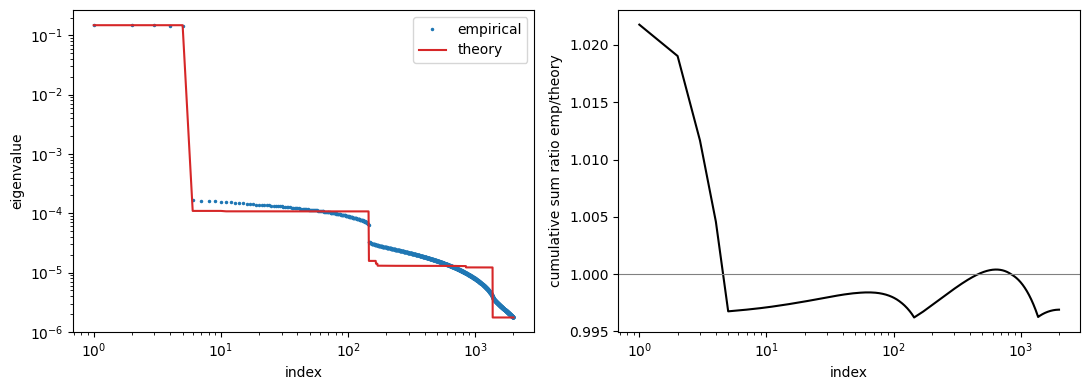

In [ ]:
n_sp = 1500 if SMOKE else 6000
rng = np.random.default_rng(7)
s_sp = ST.sample(cfg, n_sp, rng, betas, WHITEN_X, WHITEN_SCALE)
krr = ST.StructuredKRR(WIDTH, 0.0, 1.0 / (cfg.dim * cfg.v), DEVICE)
Csp, Qsp = krr._t(ST.context_vec(s_sp)), krr._t(s_sp["xq"])
ev = torch.linalg.eigvalsh(krr.gram(Csp, Qsp, Csp, Qsp)).cpu().numpy()[::-1] / n_sp
del Csp, Qsp
top = min(2000, n_sp // 2)
th_sp = theory.spectrum(sy, top)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(np.arange(1, top + 1), ev[:top], ".", ms=3, label="empirical")
ax[0].loglog(np.arange(1, top + 1), th_sp, "-", color="tab:red", label="theory")
ax[0].set_xlabel("index"); ax[0].set_ylabel("eigenvalue"); ax[0].legend()
ax[1].semilogx(np.arange(1, top + 1), np.cumsum(ev[:top]) / np.cumsum(th_sp), color="k")
ax[1].axhline(1, color="grey", lw=0.8); ax[1].set_xlabel("index"); ax[1].set_ylabel("cumulative sum ratio emp/theory")
plt.tight_layout(); plt.show()

## Train the structured kernel

In [ ]:
RUN_FILE = os.path.join(RESULTPATH, f"whitebetas_structured_krr_woverlap_{TAG}.pkl")
if RUN_KRR:
    t0 = time.time()
    emp_ID, emp_OOD = ST.krr_learning_curve(cfg, betas, WIDTH, RIDGE, NS, TRIALS, n_test=N_TEST, seed=100,
                                            whiten=WHITEN_X, wscale=WHITEN_SCALE, device=DEVICE)
    print(f"KRR: {time.time()-t0:.0f}s")
elif os.path.exists(RUN_FILE):
    with open(RUN_FILE, "rb") as fh:
        saved = pickle.load(fh)
    NS, emp_ID, emp_OOD = saved["NS"], saved["emp_ID"], saved["emp_OOD"]
th_at = theory.curves(sy, NS, RIDGE)
for j, n in enumerate(NS):
    print(f"n={n:6d}  ID {emp_ID[:, j].mean():.4f}±{emp_ID[:, j].std():.4f} (th {th_at['ID'][j]:.4f})   "
          f"OOD {emp_OOD[:, j].mean():.4f}±{emp_OOD[:, j].std():.4f} (th {th_at['OOD'][j]:.4f})")

  trial 1/20 done (1s)
  trial 2/20 done (1s)
  trial 3/20 done (2s)
  trial 4/20 done (2s)
  trial 5/20 done (3s)
  trial 6/20 done (4s)
  trial 7/20 done (4s)
  trial 8/20 done (5s)
  trial 9/20 done (5s)
  trial 10/20 done (6s)
  trial 11/20 done (7s)
  trial 12/20 done (7s)
  trial 13/20 done (8s)
  trial 14/20 done (8s)
  trial 15/20 done (9s)
  trial 16/20 done (10s)
  trial 17/20 done (10s)
  trial 18/20 done (11s)
  trial 19/20 done (11s)
  trial 20/20 done (12s)
KRR: 12s
n=    10  ID 2.1780±1.0115 (th 1.8127)   OOD 2.1679±0.9909 (th 1.8132)
n=    20  ID 1.3411±0.2079 (th 1.3265)   OOD 1.3435±0.2071 (th 1.3280)
n=    40  ID 1.1563±0.1182 (th 1.1595)   OOD 1.1599±0.1200 (th 1.1629)
n=    80  ID 1.0925±0.0465 (th 1.1002)   OOD 1.1028±0.0429 (th 1.1070)
n=   100  ID 1.0818±0.0381 (th 1.0921)   OOD 1.0936±0.0333 (th 1.1004)
n=   200  ID 1.0630±0.0341 (th 1.0807)   OOD 1.0738±0.0245 (th 1.0946)
n=   500  ID 1.0423±0.0279 (th 1.0445)   OOD 1.0584±0.0237 (th 1.0648)
n=  1000  ID 0.987

### Measured learnabilities
Fit once at $n=$ `LEARN_N`, then project the trained predictor onto the eigenfunctions under the ID
measure: $\hat{\mathcal L}_i=\sum_b\mathbb E[\hat f\,\psi_i x_{qb}/\sqrt v]\,v_{i,b}/\sum_b v_{i,b}^2$.
This is the same quantity the theory curve above predicts, so it tests $\kappa(n)$ and the
eigenvalues together (degrees 1-5; the higher modes are far from learned at any trainable $n$).

In [ ]:
if RUN_EMP_LEARN:
    t0 = time.time()
    rngL = np.random.default_rng(321)
    trL = ST.sample(cfg, int(LEARN_N), rngL, betas, WHITEN_X, WHITEN_SCALE)
    mdl = ST.StructuredKRR(WIDTH, RIDGE, 1.0 / (cfg.dim * cfg.v), DEVICE).fit(
        ST.context_vec(trL), trL["xq"], trL["yq"] / math.sqrt(cfg.norm2))
    empL = ST.mc_learnability(theory, sy, betas, lambda s: mdl.predict(ST.context_vec(s), s["xq"]),
                              n=(20_000 if SMOKE else EMP_LEARN_MC), max_level=4)
    thL = theory.learnability(sy, [float(LEARN_N)], RIDGE)
    print(f"n = {LEARN_N}, {time.time()-t0:.0f}s")
    print(f"{'degree':>6} {'theory L':>10} {'measured L':>12}")
    for p in empL["deg_L"]:
        print(f"{p:6d} {thL['deg_L'][p][0]:10.4f} {empL['deg_L'][p]:12.4f}")
    print(f"\n{'lambda':>10} {'deg':>4}  {'dominant feature':22s} {'theory':>8} {'measured':>10} {'+-':>8}")
    sub = np.where(empL["mask"])[0]
    for k in np.argsort(empL["power"])[::-1][:12]:
        print(f"{sy['lam'][sub[k]]:10.3e} {empL['deg'][k]:4d}  {sy['dom'][sub[k]][:22]:22s} "
              f"{thL['L'][0, sub[k]]:8.4f} {empL['L'][k]:10.4f} {empL['L_se'][k]:8.4f}")
    del mdl

n = 28416, 3s
degree   theory L   measured L
     1     1.0000  129639.2851
     3     0.9747       0.9627
     5     0.0077       0.0266

    lambda  deg  dominant feature         theory   measured       +-
 1.572e-05    3  M[x4y]                   0.9741     0.9781   0.0072
 1.572e-05    3  M[x1y]                   0.9741     0.9330   0.0072
 1.572e-05    3  M[x2y]                   0.9741     0.9850   0.0078
 1.572e-05    3  M[x0y]                   0.9741     0.9536   0.0072
 1.410e-05    3  M[yy]                    0.9712     0.9609   0.0076
 1.095e-04    3  M[yy]                    0.9962     0.9736   0.0151
 1.032e-09    5  M[x2y]*M[yy]             0.0025    -0.0027   0.0227
 1.101e-09    5  M[x0y]*M[yy]             0.0026     0.0135   0.0227
 1.095e-09    5  M[x2y]*M[x2y]            0.0026     0.0286   0.0285
 1.297e-09    5  M[x2y]*M[yy]             0.0031     0.0451   0.0307
 1.519e-09    5  M[x1y]*M[yy]             0.0036     0.0726   0.0300
 9.181e-10    5  M[x0y]*M[x0y]   

## Overlap with the oracles

How much does the trained kernel *look like* each oracle, as opposed to matching its error? For a
measure $m$ (the pool for ID, the prior for OOD),
$$\cos_m(\hat f, f_{\rm o}) = \frac{\langle \hat f, f_{\rm o}\rangle_m}{\|\hat f\|_m\,\|f_{\rm o}\|_m}.$$

Theory: the learned function has mean coefficients $\mathcal L_i v_{i,b}$ on the modes, so
$\langle\hat f,f_{\rm o}\rangle_m=\sum_{i,b}\mathcal L_i v_{i,b}c^m_{i,b}$ with $c^m$ the oracle's own
mode coefficients (Monte Carlo, degrees $\le5$), and
$\|\hat f\|^2_m=(\mathcal LV)^\top G_m(\mathcal LV)+\frac{\text{ID error}}{n}\sum_k m_kG_{m,kk}\mathcal L_k^2$,
with $G_m=I$ (ID) or $S$ (OOD). The second term is the noise the fit picks up across the whole
spectrum, and it is what holds the cosines down at small $n$.

Measurement needs no eigensystem: fit at $n$, then evaluate $\hat f$, Ridge and dMMSE on the same
fresh contexts and take $\mathbb E[\hat f f_{\rm o}]/\sqrt{\mathbb E[\hat f^2]\mathbb E[f_{\rm o}^2]}$.
Both oracles use the same sampler, so `WHITEN_X` applies to them too.

As $n\to\infty$ the Ridge curve tends to the cosine between Ridge and dMMSE *restricted to the learned
span*, so it approaches the dotted $\cos(f_{\rm dMMSE},f_{\rm ridge})$ line from above, the gap being
dMMSE's power at degrees the kernel never reaches.

In [ ]:
proj = ST.oracle_projections(theory, sy, betas, n_mc=(20_000 if SMOKE else PROJ_MC), max_level=4)
ov = ST.overlap_curves(theory, sy, proj, N_THEORY, RIDGE)
for side in ("ID", "OOD"):
    p = proj[side]
    print(f"{side}: |f_ridge|^2 {p['nR']:.4f}  |f_dMMSE|^2 {p['nM']:.4f}  "
          f"cos(ridge, dMMSE) {p['cos_RM']:.4f}")
print(f"\n{'n':>9} {'cosR (ID)':>10} {'cosM (ID)':>10} {'cosR (OOD)':>11} {'cosM (OOD)':>11} "
      f"{'signal':>8} {'noise':>8}")
for n in [1e2, 1e3, 1e4, 1e5, 1e6, 1e8, 1e10, 1e12, 1e15, 1e18]:
    k = int(np.argmin(np.abs(np.log(N_THEORY / n))))
    print(f"{N_THEORY[k]:9.2e} {ov['ID']['cos_ridge'][k]:10.4f} {ov['ID']['cos_dmmse'][k]:10.4f} "
          f"{ov['OOD']['cos_ridge'][k]:11.4f} {ov['OOD']['cos_dmmse'][k]:11.4f} "
          f"{ov['ID']['signal'][k]:8.4f} {ov['ID']['noise'][k]:8.4f}")
for side in ("ID", "OOD"):
    c = ov[side]["cos_ridge"]; k = int(np.argmax(c))
    print(f"{side}: ridge cosine peaks {c[k]:.4f} at n={N_THEORY[k]:.2e}, ends {c[-1]:.4f} "
          f"(= cos(ridge, dMMSE) {proj[side]['cos_RM']:.4f}); dMMSE cosine ends "
          f"{ov[side]['cos_dmmse'][-1]:.4f}")

ID: |f_ridge|^2 0.3931  |f_dMMSE|^2 0.5003  cos(ridge, dMMSE) 0.8851
OOD: |f_ridge|^2 0.3903  |f_dMMSE|^2 0.3683  cos(ridge, dMMSE) 0.8032

        n  cosR (ID)  cosM (ID)  cosR (OOD)  cosM (OOD)   signal    noise
 9.93e+01     0.0690     0.0651      0.0596      0.0522   0.0012   0.1237
 9.87e+02     0.4384     0.3970      0.4173      0.3448   0.0568   0.2092
 9.80e+03     0.8319     0.7411      0.8248      0.6676   0.3313   0.1445
 9.74e+04     0.9645     0.8607      0.9597      0.7785   0.3889   0.0276
 1.02e+06     0.9883     0.8965      0.9818      0.8178   0.3961   0.0056
 1.01e+08     0.9474     0.9397      0.8594      0.8706   0.4362   0.0010
 9.97e+09     0.9412     0.9411      0.8378      0.8675   0.4429   0.0001
 9.84e+11     0.9411     0.9411      0.8376      0.8675   0.4430   0.0000
 1.02e+15     0.9411     0.9411      0.8376      0.8675   0.4430   0.0000
 1.00e+18     0.9411     0.9411      0.8376      0.8675   0.4430   0.0000
ID: ridge cosine peaks 0.9883 at n=1.02e+06, e

In [ ]:
if RUN_OVERLAP:
    t0 = time.time()
    OV_NS = [n for n in NS if n >= (50 if SMOKE else 500)]
    empov = ST.krr_overlap_curve(cfg, betas, WIDTH, RIDGE, OV_NS, trials=OVERLAP_TRIALS,
                                 n_mc=(10_000 if SMOKE else OVERLAP_MC), whiten=WHITEN_X,
                                 wscale=WHITEN_SCALE, device=DEVICE)
    print(f"measured overlaps: {time.time()-t0:.0f}s")
    for j, n in enumerate(OV_NS):
        k = int(np.argmin(np.abs(np.log(N_THEORY / n))))
        print(f"n={n:6d}  ID  ridge {empov[('ID','cos_ridge')][:, j].mean():.4f} "
              f"(th {ov['ID']['cos_ridge'][k]:.4f})  dMMSE {empov[('ID','cos_dmmse')][:, j].mean():.4f} "
              f"(th {ov['ID']['cos_dmmse'][k]:.4f})   OOD ridge {empov[('OOD','cos_ridge')][:, j].mean():.4f} "
              f"(th {ov['OOD']['cos_ridge'][k]:.4f})  dMMSE {empov[('OOD','cos_dmmse')][:, j].mean():.4f} "
              f"(th {ov['OOD']['cos_dmmse'][k]:.4f})")

  overlap trial 1/2 done (13s)
  overlap trial 2/2 done (25s)
measured overlaps: 25s
n=   500  ID  ridge 0.2419 (th 0.2764)  dMMSE 0.2315 (th 0.2536)   OOD ridge 0.2101 (th 0.2544)  dMMSE 0.1831 (th 0.2140)
n=  1000  ID  ridge 0.4010 (th 0.4384)  dMMSE 0.3669 (th 0.3970)   OOD ridge 0.3849 (th 0.4173)  dMMSE 0.3238 (th 0.3448)
n=  2000  ID  ridge 0.6045 (th 0.6140)  dMMSE 0.5411 (th 0.5507)   OOD ridge 0.5923 (th 0.5990)  dMMSE 0.4866 (th 0.4889)
n=  5000  ID  ridge 0.7400 (th 0.7632)  dMMSE 0.6638 (th 0.6809)   OOD ridge 0.7334 (th 0.7541)  dMMSE 0.6033 (th 0.6113)
n= 10000  ID  ridge 0.8183 (th 0.8319)  dMMSE 0.7293 (th 0.7411)   OOD ridge 0.8136 (th 0.8248)  dMMSE 0.6676 (th 0.6676)
n= 20000  ID  ridge 0.8755 (th 0.8885)  dMMSE 0.7809 (th 0.7912)   OOD ridge 0.8722 (th 0.8825)  dMMSE 0.7121 (th 0.7140)


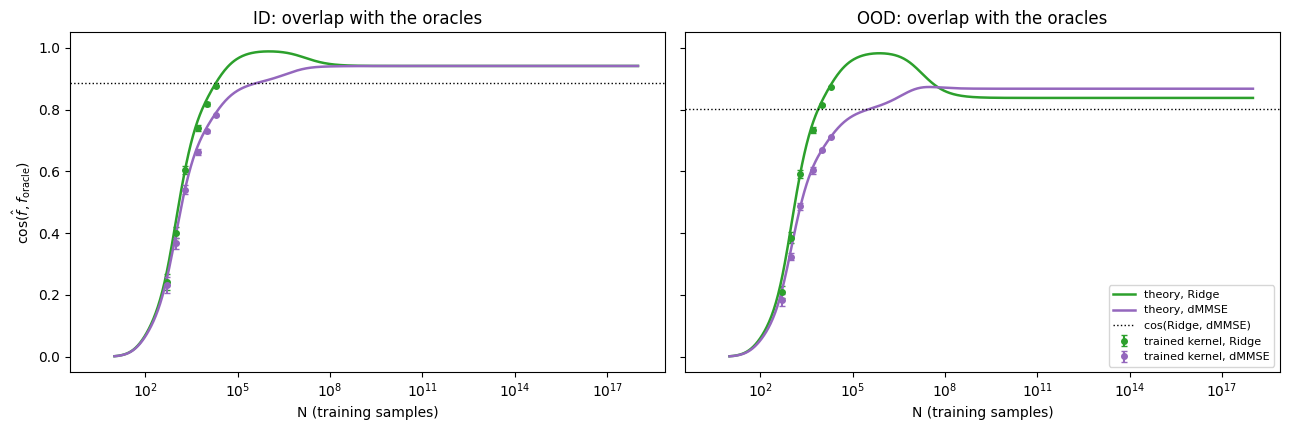

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, side in zip(axes, ("ID", "OOD")):
    for o, lab, col in (("cos_ridge", "Ridge", "tab:green"), ("cos_dmmse", "dMMSE", "tab:purple")):
        ax.semilogx(N_THEORY, ov[side][o], color=col, lw=1.8, label=f"theory, {lab}")
        if RUN_OVERLAP:
            ax.errorbar(OV_NS, empov[(side, o)].mean(0), yerr=empov[(side, o)].std(0), fmt="o", ms=4,
                        color=col, capsize=2, label=f"trained kernel, {lab}")
    ax.axhline(proj[side]["cos_RM"], color="k", ls=":", lw=1.0, label="cos(Ridge, dMMSE)")
    ax.set_xlabel("N (training samples)"); ax.set_title(f"{side}: overlap with the oracles")
    ax.set_ylim(-0.05, 1.05)
axes[0].set_ylabel(r"$\cos(\hat f, f_{\rm oracle})$"); axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIGDIR, f"whitebetas_overlaps_{TAG}.pdf"), bbox_inches="tight")
plt.show()

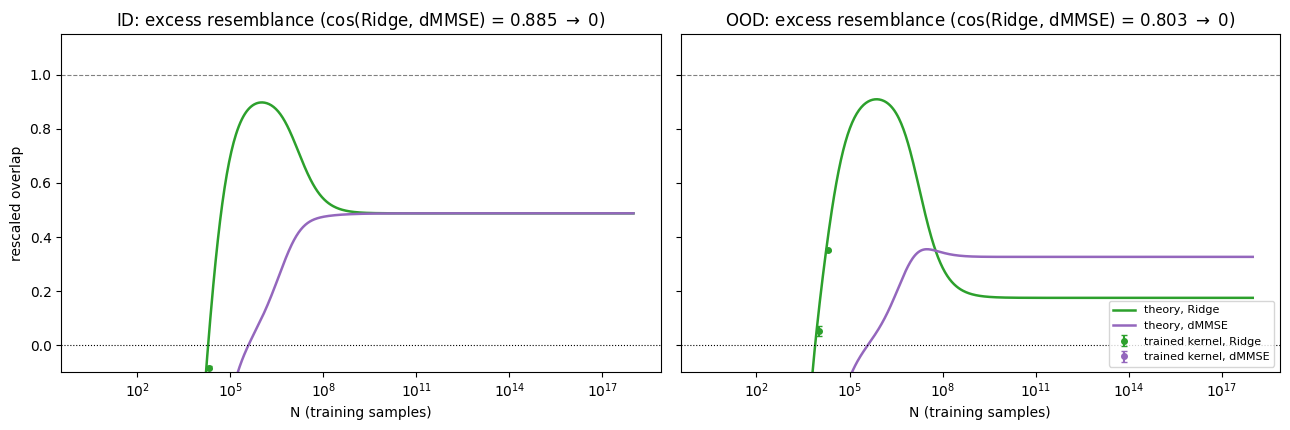

In [ ]:
# Rescaled overlaps: 0 = as close to this oracle as the other oracle is, 1 = exactly this oracle.
# s(c) = (c - cos(Ridge, dMMSE)) / (1 - cos(Ridge, dMMSE)), which divides out the component the two
# oracles share -- the part that makes the raw cosines rise together.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, side in zip(axes, ("ID", "OOD")):
    cRM = proj[side]["cos_RM"]
    resc = lambda c: (np.asarray(c) - cRM) / (1.0 - cRM)
    for o, lab, col in (("cos_ridge", "Ridge", "tab:green"), ("cos_dmmse", "dMMSE", "tab:purple")):
        ax.semilogx(N_THEORY, resc(ov[side][o]), color=col, lw=1.8, label=f"theory, {lab}")
        if RUN_OVERLAP:
            ax.errorbar(OV_NS, resc(empov[(side, o)].mean(0)), yerr=empov[(side, o)].std(0) / (1 - cRM),
                        fmt="o", ms=4, color=col, capsize=2, label=f"trained kernel, {lab}")
    ax.axhline(1.0, color="grey", lw=0.8, ls="--")
    ax.axhline(0.0, color="k", lw=0.8, ls=":")
    ax.set_xlabel("N (training samples)")
    ax.set_title(f"{side}: excess resemblance (cos(Ridge, dMMSE) = {cRM:.3f} $\\to$ 0)")
    ax.set_ylim(-0.1, 1.15)
axes[0].set_ylabel("rescaled overlap")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIGDIR, f"whitebetas_overlaps_rescaled_{TAG}.pdf"), bbox_inches="tight")
plt.show()

## Samples vs test error
Theory to $n=10^9$, trained kernel (mean ± SD over trials), Ridge and dMMSE as horizontal lines,
and the $n\to\infty$ floors at each degree cutoff as dotted lines.

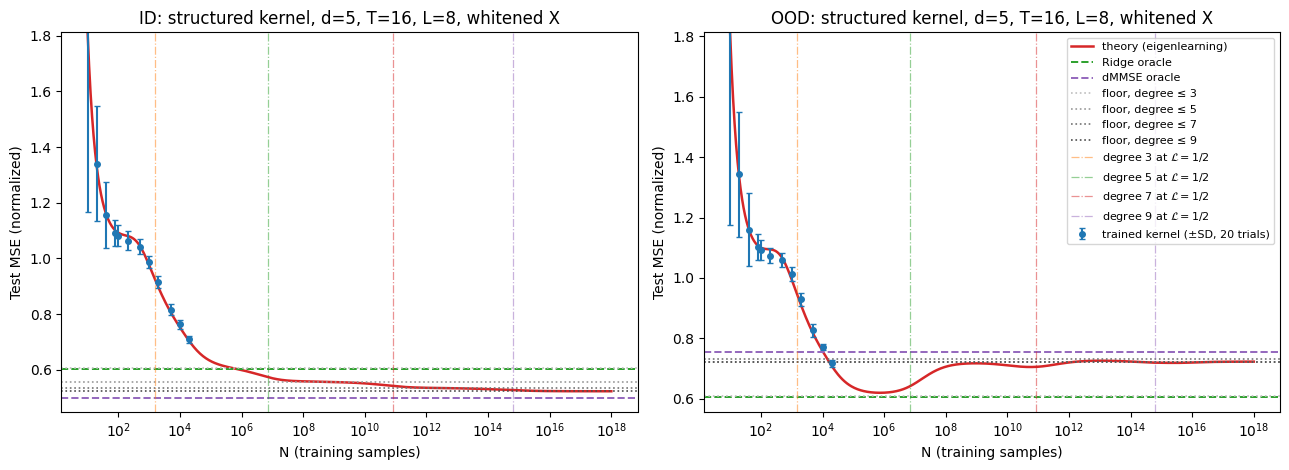

In [ ]:
wlabel = ", whitened X" if WHITEN_X else ""
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, side in zip(axes, ("ID", "OOD")):
    key = side.lower()
    ax.plot(N_THEORY, curve[side], color="tab:red", lw=1.8, label="theory (eigenlearning)")
    ax.errorbar(NS, emp_ID.mean(0) if side == "ID" else emp_OOD.mean(0),
                yerr=emp_ID.std(0) if side == "ID" else emp_OOD.std(0),
                fmt="o", ms=4, color="tab:blue", capsize=2, label=f"trained kernel (±SD, {TRIALS} trials)")
    ax.axhline(ORC[f"ridge_{key}"], color="tab:green", ls="--", lw=1.4, label="Ridge oracle")
    ax.axhline(ORC[f"dmmse_{key}"], color="tab:purple", ls="--", lw=1.4, label="dMMSE oracle")
    for cut, shade in zip(range(2, MAX_LEVEL + 1, 2), (0.75, 0.6, 0.45, 0.3)):
        ax.axhline(FLOORS[cut][0 if side == "ID" else 1], color=str(shade), ls=":", lw=1.2,
                   label=f"floor, degree ≤ {cut+1}")
    for p, nh in learn["deg_n_half"].items():            # where each degree is half learned
        if np.isfinite(nh) and p > 1:
            ax.axvline(nh, color=plt.cm.tab10(list(learn["deg_L"]).index(p)), ls="-.", lw=0.9, alpha=0.5,
                       label=rf"degree {p} at $\mathcal{{L}}=1/2$")
    ax.set_xscale("log"); ax.set_xlabel("N (training samples)"); ax.set_ylabel("Test MSE (normalized)")
    ax.set_title(f"{side}: structured kernel, d={DIM}, T={T}, L={L_CFG}{wlabel}")
    lo = min(curve[side].min(), ORC[f"ridge_{key}"], ORC[f"dmmse_{key}"])
    ax.set_ylim(lo - 0.05, max(1.3, ORC[f"dmmse_{key}"] + 0.1, min(curve[side].max(), 2.0)))
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
FIGDIR = os.path.join(RESULTPATH, "figs"); os.makedirs(FIGDIR, exist_ok=True)
plt.savefig(os.path.join(FIGDIR, f"whitebetas_structured_curves_{TAG}.pdf"), bbox_inches="tight")
plt.show()

In [ ]:
with open(RUN_FILE, "wb") as fh:
    pickle.dump(dict(config=dict(DIM=DIM, L_CFG=L_CFG, EPS2=EPS2, SIGMA_X2=cfg.v, T=T, POOL_KIND=POOL_KIND,
                                 POOL_SEED=POOL_SEED, WIDTH=WIDTH, RIDGE=RIDGE, MAX_LEVEL=MAX_LEVEL,
                                 WHITEN_X=WHITEN_X, WHITEN_SCALE=WHITEN_SCALE),
                     betas=betas, NS=NS, emp_ID=emp_ID, emp_OOD=emp_OOD, th_n=N_THEORY,
                     th_ID=curve["ID"], th_OOD=curve["OOD"], floors=FLOORS, oracles=ORC,
                     lam=sy["lam"], level=sy["level"], v_tr=sy["v_tr"], dom=sy["dom"],
                     kappa=learn["kappa"], learn_L=learn["L"], learn_power=learn["power"],
                     learn_n_half=learn["n_half"], learn_deg_L=learn["deg_L"],
                     learn_deg_n_half=learn["deg_n_half"], learn_deg_power=learn["deg_power"],
                     emp_learn=(empL if RUN_EMP_LEARN else None),
                     emp_learn_n=(LEARN_N if RUN_EMP_LEARN else None),
                     overlap_theory=ov, overlap_oracles={k: proj[k] for k in ("ID", "OOD")},
                     overlap_emp=(empov if RUN_OVERLAP else None),
                     overlap_ns=(OV_NS if RUN_OVERLAP else None)), fh)
print("saved", RUN_FILE)

saved /content/drive/MyDrive/results/structured_kernel/whitebetas_structured_krr_woverlap_d5_L8_e0.1_T16_whiten_s0_w3_r0.01_whiten.pkl
